# 01 · Data exploration (tasks T07 to T10)

The hand-labelled subset of **Sen1Floods11**: 446 Sentinel-1 chips of 512×512 pixels (10 m per pixel, about 5 km × 5 km) from 11 flood events, each with a water mask drawn by a person.

This notebook checks that the files and splits are complete (T07), looks at the images (T08), measures the things that later design choices rest on (T09) and verifies the normalisation statistics (T10).

**Rule followed throughout:** anything that feeds a decision is computed on the **training split only**. Validation, test and Bolivia images are never displayed or analysed here; for those splits only label bookkeeping (how many chips, how many labelled pixels) is reported, for the dataset table of the report.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from src import data_stats, viz
from src.data import LABEL_DIR, S1_DIR, SPLITS, list_split, load_split
from src.norm_stats import compute_norm_stats
from src.preprocess import CHANNELS, CLIP_DB, NORM_JSON, load_norm_stats, preprocess

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
RESULTS, FIG = ROOT / "results", ROOT / "figures" / "eda"

## 1. Are the files and splits complete? (T07)

Expected: 446 radar chips, 446 labels, and four split lists of 252 (train), 89 (validation), 90 (test) and 15 (Bolivia) chips that together cover every chip exactly once.

In [2]:
integrity = data_stats.check_integrity()          # raises if anything is missing, duplicated or miscounted
(RESULTS / "data_integrity.json").write_text(json.dumps(integrity, indent=2) + "\n")

print("radar chips on disk :", integrity["s1_files_on_disk"])
print("label files on disk :", integrity["label_files_on_disk"])
print("chips per split     :", integrity["chips_per_split"], "-> total", integrity["chips_in_all_splits"],
      "| unique", integrity["unique_chips_in_all_splits"])
print("listed but missing  :", integrity["files_listed_but_missing"] or "none")
print("in two splits       :", integrity["chips_in_more_than_one_split"] or "none")
print("on disk, in no split:", integrity["chips_on_disk_not_in_any_split"] or "none")

radar chips on disk : 446
label files on disk : 446
chips per split     : {'train': 252, 'val': 89, 'test': 90, 'bolivia': 15} -> total 446 | unique 446
listed but missing  : none
in two splits       : none
on disk, in no split: none


In [3]:
events = pd.DataFrame(integrity["events_per_split"]).fillna(0).astype(int)
events.loc["total"] = events.sum()
events

,train,val,test,bolivia
Ghana,31,11,11,0
India,40,14,14,0
Mekong,18,6,6,0
Nigeria,10,4,4,0
Pakistan,16,6,6,0
Paraguay,39,14,14,0
Somalia,15,5,6,0
Spain,18,6,6,0
Sri-Lanka,24,9,9,0
USA,41,14,14,0


All counts match. Train, validation and test are drawn from the same ten flood events; **Bolivia appears in none of them**, which is what makes it a test of generalisation to an unseen flood (RQ4).

## 2. What is inside one chip? (T08, step 2)

In [4]:
s1_path, label_path = list_split("train")[0]
with rasterio.open(s1_path) as f:
    img = f.read()
    print(s1_path.name)
    print("  shape        :", img.shape, img.dtype)
    print("  band names   :", f.descriptions)
    print("  CRS          :", f.crs, "| pixel size (deg):", tuple(round(abs(v), 7) for v in f.res))
    print("  nodata value :", f.nodata)
with rasterio.open(label_path) as f:
    lab = f.read(1)
    print(label_path.name)
    print("  shape        :", lab.shape, lab.dtype, "| values:", np.unique(lab).tolist())
print("mean VV %.1f dB, mean VH %.1f dB" % (np.nanmean(img[0]), np.nanmean(img[1])))

Ghana_103272_S1Hand.tif
  shape        : (2, 512, 512) float32
  band names   : ('VV', 'VH')
  CRS          : EPSG:4326 | pixel size (deg): (8.98e-05, 8.98e-05)
  nodata value : nan
Ghana_103272_LabelHand.tif
  shape        : (512, 512) int16 | values: [-1, 0, 1]
mean VV -9.2 dB, mean VH -15.2 dB


Band 1 is **VV** and band 2 is **VH** (the files say so in their band descriptions, and VH is several dB lower, as cross-polarised returns always are). Values are backscatter in dB; missing radar pixels are NaN. Labels are −1 (no data), 0 (not water), 1 (water).

## 3. Look at the data (T08)

Six training chips from six different events. For each event the chip whose water share is closest to 20% is shown (a fixed rule, so the figure is reproducible). Both radar bands use the same fixed dB range in every panel, so brightness is comparable between chips.

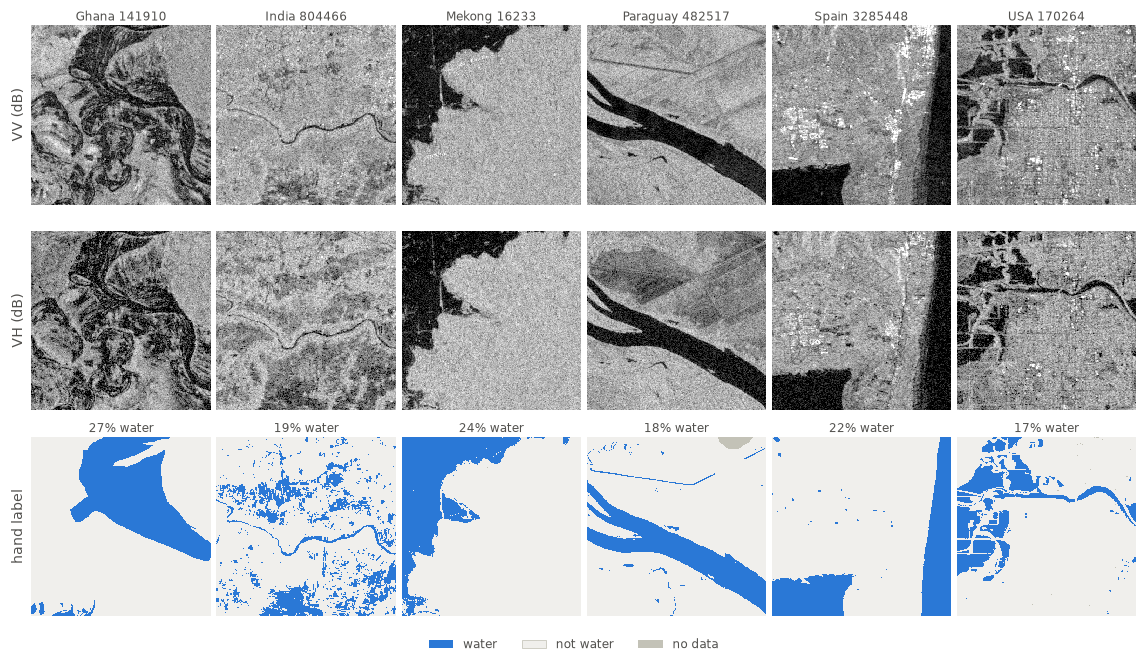

In [5]:
train = data_stats.chip_table("train")
sample = data_stats.pick_sample_chips(train)
fig = data_stats.plot_sample_chips(sample)
viz.savefig(fig, FIG / "sample_chips.png")
plt.show()

**Why water looks dark.** The radar looks at the ground from the side. Calm water is smooth, so it reflects the pulse away from the satellite like a mirror and almost nothing comes back; rough surfaces such as vegetation, soil and buildings scatter part of the pulse back and appear bright.

Other things worth noticing: VH shows water more cleanly than VV (in VV, wind-roughened water can be as bright as land); the masks contain thin rivers and ragged shorelines that are only a few pixels wide; and some dark patches in the radar image are *not* labelled as water.

## 4. Statistics of the training set (T09)

### 4.1 How much of the data is water?

In [6]:
train.to_csv(RESULTS / "data_stats.csv", index=False)
summary = {**data_stats.summarise_split(train, "train"), "clip_db": list(CLIP_DB), **data_stats.clip_counts("train"),
           "chips_per_water_class": data_stats.water_bins(train).to_dict()}
(RESULTS / "data_summary.json").write_text(json.dumps(summary, indent=2) + "\n")

print(f"training chips                       : {summary['n_chips']}")
print(f"labelled (valid) pixels              : {summary['n_valid_px']:,}")
print(f"water share of labelled pixels       : {summary['water_share_of_valid_px']:.2%}")
print(f"chips with no water at all           : {summary['chips_no_water']}")
print(f"chips with less than 1% water        : {summary['chips_water_below_1pct']}  (includes the chips with none)")
print(f"chips with less than 5% water        : {summary['chips_water_below_5pct']}")
print(f"median water share of a chip         : {summary['median_chip_water_frac']:.2%}")
train.sort_values("water_frac", ascending=False).head(5)

training chips                       : 252
labelled (valid) pixels              : 57,303,407
water share of labelled pixels       : 9.51%
chips with no water at all           : 32
chips with less than 1% water        : 89  (includes the chips with none)
chips with less than 5% water        : 159
median water share of a chip         : 2.49%


,chip,event,n_pixels,n_valid,n_water,water_frac,n_label_nodata,n_nan_image,n_nan_image_valid_label,vv_mean_db,vh_mean_db
191,Sri-Lanka_845821,Sri-Lanka,262144,240758,234546,0.9742,21386,0,0,-12.2257,-26.3745
169,Spain_5923267,Spain,262144,218743,201713,0.9221,43401,0,0,-22.9650,-31.9904
89,Nigeria_529525,Nigeria,262144,262144,223651,0.8532,0,0,0,-15.7945,-23.0650
72,Mekong_52610,Mekong,262144,262144,210673,0.8037,0,0,0,-16.7334,-25.8899
88,Mekong_1248200,Mekong,262144,260988,204588,0.7839,1156,0,0,-15.6735,-24.9699


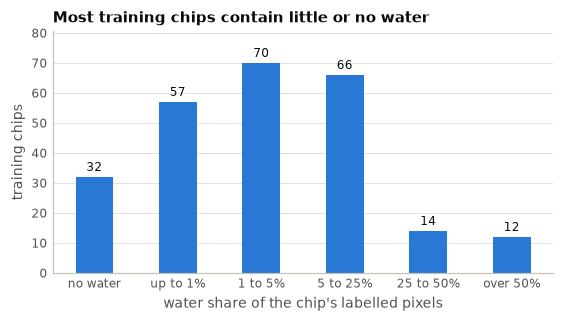

In [7]:
ax = data_stats.plot_water_fraction(train)
ax.figure.tight_layout()
viz.savefig(ax.figure, FIG / "water_fraction_per_chip.png")
plt.show()

In [8]:
per_event = train.groupby("event").agg(chips=("chip", "size"), valid_px=("n_valid", "sum"), water_px=("n_water", "sum"),
                                       chips_without_water=("n_water", lambda s: int((s == 0).sum())))
per_event["water share"] = per_event["water_px"] / per_event["valid_px"]
per_event.sort_values("water share", ascending=False)[["chips", "chips_without_water", "water share"]]

,chips,chips_without_water,water share
event,,,
Mekong,18,1,0.2999
Nigeria,10,0,0.2403
Sri-Lanka,24,2,0.1085
Spain,18,0,0.0827
India,40,1,0.0827
Paraguay,39,6,0.0803
Somalia,15,3,0.0738
USA,41,0,0.0561
Pakistan,16,4,0.0397


Water is a small minority: under 10% of the labelled training pixels, and 159 of the 252 chips have less than 5% water. A model could reach about 90% pixel accuracy by never predicting water. Two consequences:

* **accuracy is the wrong metric**; the project reports water IoU, precision and recall instead;
* a plain per-pixel loss (BCE) is dominated by the easy "not water" pixels, which is why experiment **E2** compares it with Dice, a loss that measures overlap with the water class directly.

The water share also differs strongly between events, so scores averaged per chip and scores pooled over all pixels will not agree; both are reported.

### 4.2 Can a single threshold separate water from land?

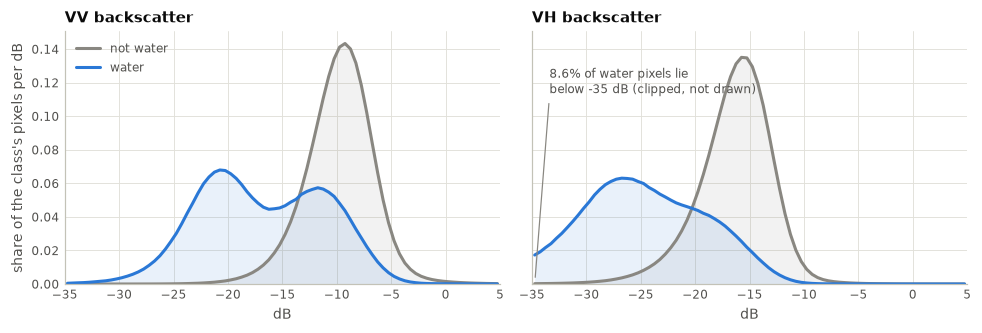

In [9]:
hist = data_stats.db_histograms("train")
hist.to_csv(RESULTS / "db_histograms.csv", index=False)
axes = data_stats.plot_db_histograms(hist)
axes[0].figure.tight_layout()
viz.savefig(axes[0].figure, FIG / "hist_vv_vh_water.png")
plt.show()

In [10]:
def overlap(band):
    """Shared area of the two normalised class histograms: 0 = perfectly separable, 1 = identical."""
    h = hist[hist["band"] == band]
    w = h[h["class"] == "water"]["count"].to_numpy(float)
    n = h[h["class"] == "not_water"]["count"].to_numpy(float)
    return float(np.minimum(w / w.sum(), n / n.sum()).sum())

pd.Series({"VV": overlap("VV"), "VH": overlap("VH")}, name="histogram overlap, water vs not water").to_frame()

,"histogram overlap, water vs not water"
VV,0.4392
VH,0.3441


Water sits lower (darker) than land in both bands, but the two distributions overlap: the classes are *not* cleanly separable by one number.

* In **VH** the overlap is smaller, which is why the threshold baseline (E0, Otsu) uses VH.
* In **VV** the water distribution has two humps. The brighter one overlaps land almost completely: this is water roughened by wind or broken by vegetation, which VV picks up strongly.

So a threshold is a fair, simple baseline that should work on open water and fail where water is bright or land is dark, and there is room for a model that uses spatial context and both bands (RQ1).

### 4.3 Missing data

In [11]:
missing = pd.Series({
    "pixels in the training chips": summary["n_pixels"],
    "label = -1 (no data)": summary["n_label_nodata_px"],
    "  share of all pixels": summary["label_nodata_share"],
    "radar value is NaN": summary["n_nan_image_px"],
    "  share of all pixels ": summary["nan_image_share"],
    "NaN radar but labelled 0 or 1": summary["n_nan_image_px_with_valid_label"],
    "radar values below -35 dB (clipped)": summary["n_below_clip"],
    "radar values above 5 dB (clipped)": summary["n_above_clip"],
    "lowest / highest radar value (dB)": f"{summary['min_db']:.1f} / {summary['max_db']:.1f}",
}, name="training split")
missing.to_frame()

,training split
pixels in the training chips,66060288
label = -1 (no data),8756881
share of all pixels,0.1326
radar value is NaN,1325136
share of all pixels,0.0201
NaN radar but labelled 0 or 1,24150
radar values below -35 dB (clipped),555687
radar values above 5 dB (clipped),31455
lowest / highest radar value (dB),-79.2 / 29.9


In [12]:
splits = pd.DataFrame([data_stats.summarise_split(train if s == "train" else data_stats.chip_table(s), s) for s in SPLITS])
splits.to_csv(RESULTS / "split_summary.csv", index=False)
splits.set_index("split")[["n_chips", "n_events", "n_valid_px", "water_share_of_valid_px", "label_nodata_share",
                           "nan_image_share", "n_nan_image_px_with_valid_label", "chips_without_any_sar_data"]]

,n_chips,n_events,n_valid_px,water_share_of_valid_px,label_nodata_share,nan_image_share,n_nan_image_px_with_valid_label,chips_without_any_sar_data
split,,,,,,,,
train,252,10,57303407,0.0951,0.1326,0.0201,24150,0
val,89,10,20294725,0.1103,0.1301,0.0094,20571,0
test,90,10,20517367,0.1251,0.1304,0.0238,73408,1
bolivia,15,1,2867815,0.1586,0.2707,0.1033,43381,0


* **13% of the training pixels have no label (−1).** They are masked out of the loss and of every metric.
* **2% of the radar pixels are NaN.** Almost all of them also have no label. They are replaced by 0 *after* standardising, i.e. by the average training pixel.
* A small number of pixels have a label but **no radar value**. No method can classify those from the image. They are kept in the scores (the usual convention: every labelled pixel counts), and the evaluation also reports scores without them.
* The split table is label bookkeeping only. It does show one thing that matters for reading the results later: **one test chip has no radar data at all** although part of it is labelled.
* Radar values run from about −79 to +30 dB; clipping to [−35, 5] dB touches under 0.5% of the values, mostly very dark water in VH.

## 5. Normalisation statistics (T10)

`src/norm_stats.py` computes the mean and standard deviation of the three input channels (VV, VH and the ratio VV − VH, all after clipping) over the **training chips only**, ignoring NaN. Every run loads the same file.

In [13]:
stats = json.loads(NORM_JSON.read_text())
table = pd.DataFrame({"mean": stats["mean"], "std": stats["std"], "pixels": stats["n_pixels"]}, index=stats["channels"])
print("split:", stats["split"], "| chips:", stats["n_chips"], "| clip range (dB):", stats["clip_db"])
table

split: train | chips: 252 | clip range (dB): [-35.0, 5.0]


,mean,std,pixels
VV,-10.3938,4.0294,64735152
VH,-17.1980,4.5491,64735152
VV_minus_VH,6.8042,3.3084,64735152


In [14]:
# Independent check 1: recompute from the raw training images.
images = load_split("train").images
again = compute_norm_stats(images)
assert np.allclose(again["mean"], stats["mean"], atol=1e-6) and np.allclose(again["std"], stats["std"], atol=1e-6)

# Independent check 2: plain NumPy on the clipped VV band (a different code path).
vv = np.clip(images[:, 0], *CLIP_DB)
assert abs(np.nanmean(vv, dtype=np.float64) - stats["mean"][0]) < 1e-4
assert abs(np.nanstd(vv, dtype=np.float64) - stats["std"][0]) < 1e-4
del vv

# Check 3: after preprocessing, the training inputs are centred with unit spread and contain no NaN.
x = np.concatenate([preprocess(im, "vv_vh_ratio", load_norm_stats()).reshape(-1, 3) for im in images[::6]])
observed = ~np.isnan(np.clip(images[::6], *CLIP_DB)).any(axis=1).reshape(-1)
check = pd.DataFrame({"mean after standardising": x[observed].mean(axis=0), "std after standardising": x[observed].std(axis=0)},
                     index=CHANNELS)
assert not np.isnan(x).any()
print("stored statistics reproduced; standardised training inputs (every 6th chip):")
check

stored statistics reproduced; standardised training inputs (every 6th chip):


,mean after standardising,std after standardising
VV,0.0395,0.9010
VH,0.0485,0.9269
VV_minus_VH,-0.0188,0.9650


The stored statistics are reproduced by two independent calculations, and the standardised inputs are centred near 0 with a spread near 1.

## 6. What this means for the rest of the project

| Finding (training split) | Consequence |
|---|---|
| Files and splits are complete; Bolivia is absent from train / validation / test | Official splits are used as they are; Bolivia is a true held-out event |
| Water is under 10% of labelled pixels; 32 chips have none | IoU, precision and recall instead of accuracy; Dice-based default loss; E2 tests the loss |
| Water and land overlap in dB, less so in VH than in VV | Otsu on VH is a fair baseline (E0); E1 tests whether VV and the ratio add information |
| 13% of pixels unlabelled, 2% of radar pixels NaN | Loss and metrics ignore −1; NaN → 0 after standardising |
| Values outside [−35, 5] dB are rare | Clipping removes outliers without losing information |